# Pré-processamento

Aplica as transformações decididas em `consideracoes.md` (seção "Pré-processamento") que valem para a base inteira. Cada linha é transformada isoladamente, sem aprender nada com o resto da base, portanto não há vazamento entre treino e teste.

A padronização (`StandardScaler`) e os pesos de classe / priors ficam fora deste notebook, no pipeline da modelagem, dentro de cada fold.

Saídas em `data/processed/`: `churn-com-status.csv` e `churn-sem-status.csv`.

## Imports e caminhos

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RAW = '../data/raw/raw-customer-churn.csv'
PROCESSED_DIR = '../data/processed'
FIG_DIR = '../data/results/pre-processamento'
os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

# forma da base a cada etapa, para o resumo final
etapas = []
def registra(nome, d):
    etapas.append((nome, d.shape[0], d.shape[1]))

## Leitura da base bruta

In [2]:
df = pd.read_csv(RAW)
assert df.shape == (3150, 14)
registra('base bruta', df)
df.head()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


## Remover duplicatas

300 linhas são exatamente duplicadas. A remoção vem antes de tudo, sobre as colunas originais, e evita que a mesma linha caia no treino e no teste.

In [3]:
churn_antes = df['Churn'].mean()
df = df.drop_duplicates().reset_index(drop=True)

assert len(df) == 2850
assert df['Churn'].sum() == 446
print(f'churn antes: {churn_antes:.2%} | depois: {df["Churn"].mean():.2%}')
registra('sem duplicatas', df)

churn antes: 15.71% | depois: 15.65%


## Remover `Age Group`

O atributo é redundante com `Age` (correspondência 1:1), o que é confirmado nos dois sentidos antes da remoção.

In [4]:
assert df.groupby('Age Group')['Age'].nunique().eq(1).all()
assert df.groupby('Age')['Age Group'].nunique().eq(1).all()

df = df.drop(columns='Age Group')
registra('sem Age Group', df)

## Renomear colunas

Nomes em `snake_case` em português, sem os espaços duplos do CSV original (tabela em `consideracoes.md`).

In [5]:
RENOMEAR = {
    'Call  Failure': 'falhas_ligacao',
    'Complains': 'reclamacao',
    'Subscription  Length': 'meses_assinatura',
    'Charge  Amount': 'faixa_cobranca',
    'Seconds of Use': 'segundos_uso',
    'Frequency of use': 'qtd_ligacoes',
    'Frequency of SMS': 'qtd_sms',
    'Distinct Called Numbers': 'numeros_distintos',
    'Tariff Plan': 'plano_contratual',
    'Status': 'inativo',
    'Age': 'idade',
    'Customer Value': 'valor_cliente',
    'Churn': 'churn',
}
# nenhuma coluna pode ficar sem nome novo
assert set(df.columns) == set(RENOMEAR)

df = df.rename(columns=RENOMEAR)
list(df.columns)

['falhas_ligacao',
 'reclamacao',
 'meses_assinatura',
 'faixa_cobranca',
 'segundos_uso',
 'qtd_ligacoes',
 'qtd_sms',
 'numeros_distintos',
 'plano_contratual',
 'inativo',
 'idade',
 'valor_cliente',
 'churn']

## Recodificar `plano_contratual` e `inativo` para 0/1

Os dois usam 1/2 na base. Com 0/1, todos os binários seguem a convenção 1 = presença da característica:
- `plano_contratual`: 0 = pré-pago (pay as you go), 1 = contratual.
- `inativo`: 0 = ativo, 1 = inativo.

In [6]:
RECODIFICAR = {1: 0, 2: 1}
contagem = {}
for col in ['plano_contratual', 'inativo']:
    antes = df[col].value_counts()
    df[col] = df[col].map(RECODIFICAR)
    depois = df[col].value_counts()

    assert df[col].notna().all()  # nenhum valor fora de {1, 2}
    assert antes[1] == depois[0] and antes[2] == depois[1]
    contagem[col] = {'1 -> 0': depois[0], '2 -> 1': depois[1]}

pd.DataFrame(contagem)

,plano_contratual,inativo
1 -> 0,2621,2166
2 -> 1,229,684


## One-hot da idade

A relação da idade com o churn não é monotônica (churn quase zero nos grupos extremos). Com uma coluna por faixa, a regressão logística atribui um coeficiente a cada grupo. As 5 colunas são mantidas, sem categoria de referência.

In [7]:
dummies = pd.get_dummies(df['idade'], prefix='idade', dtype=int)

assert list(dummies.columns) == ['idade_15', 'idade_25', 'idade_30', 'idade_45', 'idade_55']
assert dummies.sum(axis=1).eq(1).all()  # cada cliente em exatamente uma faixa

df = pd.concat([df.drop(columns='idade'), dummies], axis=1)
registra('one-hot da idade', df)
dummies.sum().rename('clientes')

idade_15     112
idade_25     921
idade_30    1296
idade_45     367
idade_55     154
Name: clientes, dtype: int64

## `log1p` nos atributos de uso

Os atributos de uso têm forte assimetria à direita (cauda longa e muitos zeros). `log1p(x) = log(1 + x)` aceita zero e aproxima as distribuições de uma normal, o que favorece a MLP, a regressão logística e sobretudo o Naive Bayes gaussiano. No XGBoost o efeito é nulo, pois a ordem dos valores não muda.

`meses_assinatura` e `faixa_cobranca` ficam sem log, e os nomes das colunas são mantidos.

In [8]:
COLS_LOG = ['falhas_ligacao', 'segundos_uso', 'qtd_ligacoes', 'qtd_sms', 'numeros_distintos', 'valor_cliente']

antes_log = df.copy()
assert (df[COLS_LOG] >= 0).all().all()  # log1p exige x > -1

df[COLS_LOG] = np.log1p(df[COLS_LOG])

pd.DataFrame({
    'assimetria antes': antes_log[COLS_LOG].skew(),
    'assimetria depois': df[COLS_LOG].skew(),
}).round(2)

,assimetria antes,assimetria depois
falhas_ligacao,1.07,-0.48
segundos_uso,1.31,-2.79
qtd_ligacoes,1.15,-1.43
qtd_sms,1.97,-0.22
numeros_distintos,1.04,-1.21
valor_cliente,1.42,-1.34


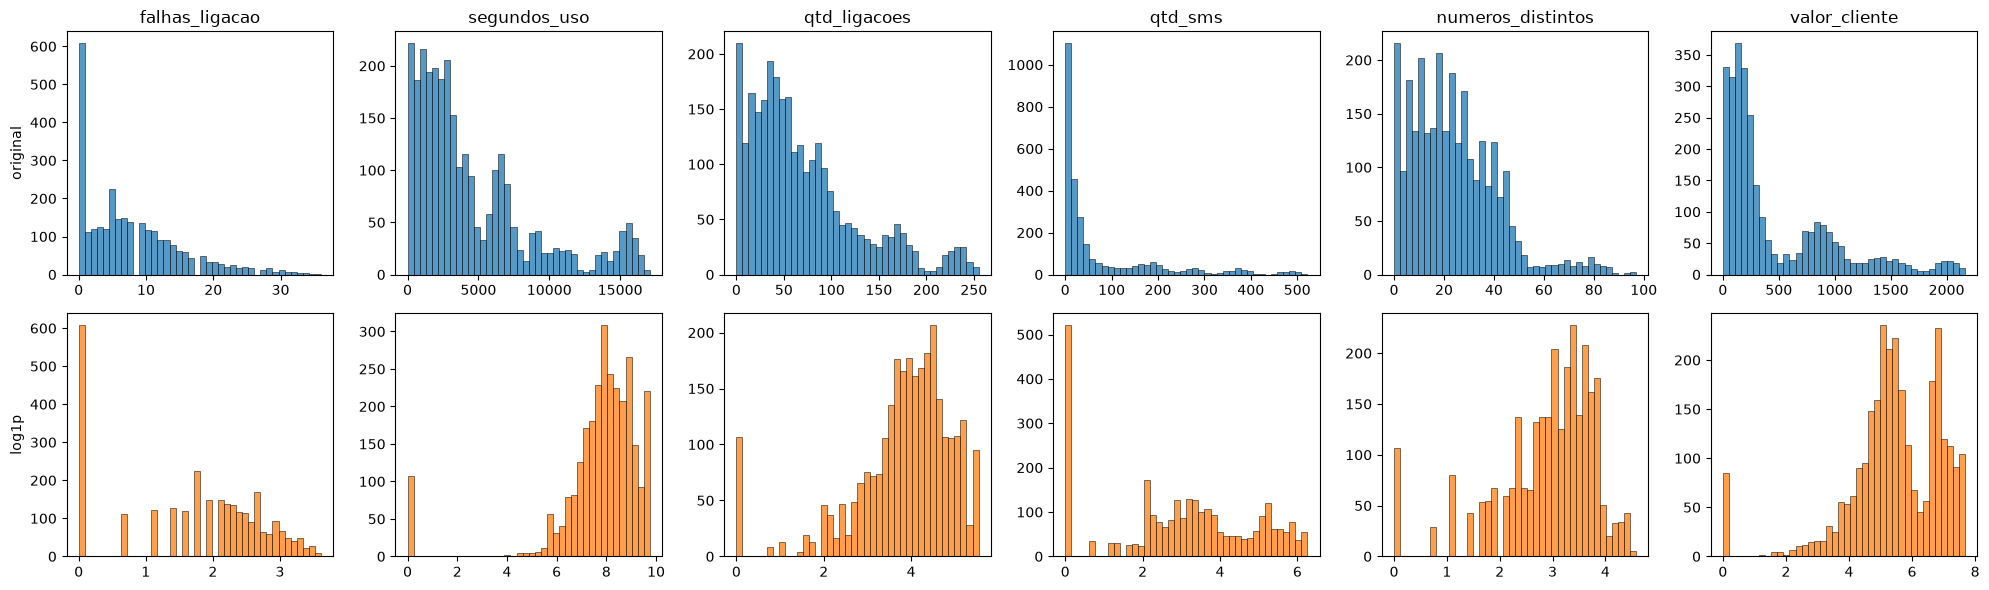

In [9]:
fig, axes = plt.subplots(2, len(COLS_LOG), figsize=(20, 6))
for i, col in enumerate(COLS_LOG):
    sns.histplot(antes_log[col], bins=40, ax=axes[0, i], color='tab:blue')
    sns.histplot(df[col], bins=40, ax=axes[1, i], color='tab:orange')
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel(''); axes[1, i].set_xlabel('')
    axes[0, i].set_ylabel('original' if i == 0 else '')
    axes[1, i].set_ylabel('log1p' if i == 0 else '')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/log1p-antes-depois.png', dpi=150, bbox_inches='tight'); plt.show()

### Redundância antes e depois do log

Critério para a versão do NB sem redundantes: um par é redundante se |r| > 0,9 nos dados que o modelo recebe (já com log). Dentro do par, sai o atributo menos correlacionado com o churn.

In [10]:
def correlacoes(d):
    return {
        'r(segundos, ligações)': d['segundos_uso'].corr(d['qtd_ligacoes']),
        'r(sms, valor_cliente)': d['qtd_sms'].corr(d['valor_cliente']),
        'r(segundos, churn)': d['segundos_uso'].corr(d['churn']),
        'r(ligações, churn)': d['qtd_ligacoes'].corr(d['churn']),
        'r(sms, churn)': d['qtd_sms'].corr(d['churn']),
        'r(valor_cliente, churn)': d['valor_cliente'].corr(d['churn']),
    }

pd.DataFrame({'sem log': correlacoes(antes_log), 'com log': correlacoes(df)}).round(3)

,sem log,com log
"r(segundos, ligações)",0.945,0.925
"r(sms, valor_cliente)",0.923,0.714
"r(segundos, churn)",-0.296,-0.340
"r(ligações, churn)",-0.299,-0.358
"r(sms, churn)",-0.219,-0.204
"r(valor_cliente, churn)",-0.287,-0.356


Depois do log, só segundos × ligações continua acima de 0,9, e sai `segundos_uso`, um pouco menos correlacionado com o churn que `qtd_ligacoes`. O par SMS × `valor_cliente` cai para ~0,71, e os dois ficam.

## Ordem das colunas e listas para a modelagem

Ordem: numéricas → binárias → one-hot → `churn`. As listas abaixo servem de referência para o `ColumnTransformer` do notebook de modelagem.

In [11]:
COLS_PADRONIZAR = ['falhas_ligacao', 'meses_assinatura', 'faixa_cobranca', 'segundos_uso',
                   'qtd_ligacoes', 'qtd_sms', 'numeros_distintos', 'valor_cliente']
COLS_BINARIAS = ['reclamacao', 'plano_contratual', 'inativo']
COLS_IDADE = ['idade_15', 'idade_25', 'idade_30', 'idade_45', 'idade_55']
COLS_PASSAR = COLS_BINARIAS + COLS_IDADE   # ficam em 0/1, sem padronização

df = df[COLS_PADRONIZAR + COLS_PASSAR + ['churn']]

COLS_NB_SEM_REDUNDANTES = [c for c in df.columns if c not in ('segundos_uso', 'churn')]

print('padronizar (MLP e regressão logística):', COLS_PADRONIZAR)
print('passar direto:', COLS_PASSAR)
print('NB sem redundantes:', COLS_NB_SEM_REDUNDANTES)

padronizar (MLP e regressão logística): ['falhas_ligacao', 'meses_assinatura', 'faixa_cobranca', 'segundos_uso', 'qtd_ligacoes', 'qtd_sms', 'numeros_distintos', 'valor_cliente']
passar direto: ['reclamacao', 'plano_contratual', 'inativo', 'idade_15', 'idade_25', 'idade_30', 'idade_45', 'idade_55']
NB sem redundantes: ['falhas_ligacao', 'meses_assinatura', 'faixa_cobranca', 'qtd_ligacoes', 'qtd_sms', 'numeros_distintos', 'valor_cliente', 'reclamacao', 'plano_contratual', 'inativo', 'idade_15', 'idade_25', 'idade_30', 'idade_45', 'idade_55']


## Checagem final

In [12]:
assert df.shape == (2850, 17)
assert df.notna().all().all()
assert all(pd.api.types.is_numeric_dtype(t) for t in df.dtypes)
assert df[COLS_PASSAR + ['churn']].isin([0, 1]).all().all()
registra('base final', df)

df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
falhas_ligacao,2850.0,1.718,1.075,0.0,0.693,1.946,2.565,3.611
meses_assinatura,2850.0,32.453,8.723,3.0,29.000,35.000,38.000,47.000
faixa_cobranca,2850.0,0.975,1.551,0.0,0.000,0.000,2.000,10.000
segundos_uso,2850.0,7.724,1.827,0.0,7.286,8.020,8.780,9.746
qtd_ligacoes,2850.0,3.826,1.161,0.0,3.367,4.016,4.575,5.545
qtd_sms,2850.0,3.002,1.878,0.0,2.079,3.135,4.489,6.260
numeros_distintos,2850.0,2.888,0.952,0.0,2.485,3.091,3.555,4.585
valor_cliente,2850.0,5.431,1.507,0.0,4.775,5.453,6.673,7.681
reclamacao,2850.0,0.081,0.272,0.0,0.000,0.000,0.000,1.000
plano_contratual,2850.0,0.080,0.272,0.0,0.000,0.000,0.000,1.000


## Salvar

- `churn-com-status.csv`: base completa.
- `churn-sem-status.csv`: sem a coluna `inativo`, para medir o vazamento do `Status`.

Os dois ficam sem padronização, que é feita no pipeline de cada fold.

In [13]:
com_status = df
sem_status = df.drop(columns='inativo')

ARQ_COM = f'{PROCESSED_DIR}/churn-com-status.csv'
ARQ_SEM = f'{PROCESSED_DIR}/churn-sem-status.csv'
com_status.to_csv(ARQ_COM, index=False)
sem_status.to_csv(ARQ_SEM, index=False)

## Releitura e resumo

In [14]:
for arq, esperado, forma in [(ARQ_COM, com_status, (2850, 17)), (ARQ_SEM, sem_status, (2850, 16))]:
    lido = pd.read_csv(arq)
    assert lido.shape == forma
    pd.testing.assert_frame_equal(lido, esperado, check_exact=False)
    print(f'{arq}: {lido.shape}, churn = {lido["churn"].mean():.2%}')

pd.DataFrame(etapas, columns=['etapa', 'linhas', 'colunas'])

../data/processed/churn-com-status.csv: (2850, 17), churn = 15.65%
../data/processed/churn-sem-status.csv: (2850, 16), churn = 15.65%


,etapa,linhas,colunas
0,base bruta,3150,14
1,sem duplicatas,2850,14
2,sem Age Group,2850,13
3,one-hot da idade,2850,17
4,base final,2850,17
